In [2]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns 
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [3]:
df = pd.read_csv(r"/Users/satwik/Downloads/Mall_Customers.csv")
print("data loaded succesfully!!")

data loaded succesfully!!


In [5]:
print(df.shape)
print(df.head())
print(df.tail())
print(df.describe)
print("Missing values : ",df.isnull().sum().sum())

(200, 5)
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
     CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
195         196  Female   35                 120                      79
196         197  Female   45                 126                      28
197         198    Male   32                 126                      74
198         199    Male   32                 137                      18
199         200    Male   30                 137                      83
<bound method NDFrame.describe of      CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0             1    M

K= 2  inertia=  269.69  silhouette=0.321
K= 3  inertia=  157.70  silhouette=0.467
K= 4  inertia=  108.92  silhouette=0.494
K= 5  inertia=   65.57  silhouette=0.555
K= 6  inertia=   55.06  silhouette=0.540
K= 7  inertia=   44.86  silhouette=0.528
K= 8  inertia=   37.23  silhouette=0.455
K= 9  inertia=   32.39  silhouette=0.457
K=10  inertia=   29.98  silhouette=0.443


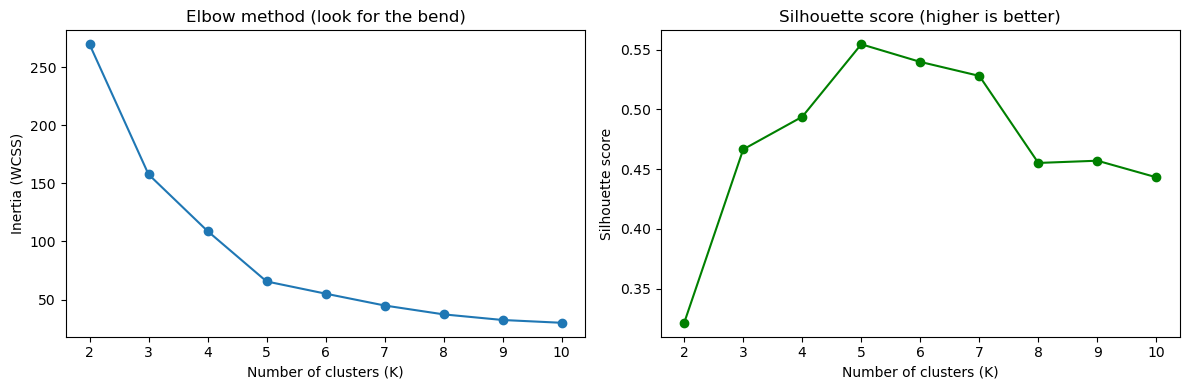

In [10]:
features = ["Annual Income (k$)", "Spending Score (1-100)"]
X = df[features]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
k_values = range(2, 11)
inertias = []
silhouettes = []
for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(X_scaled)
    inertias.append(km.inertia_)                               
    silhouettes.append(silhouette_score(X_scaled, km.labels_))
    print(f"K={k:2d}  inertia={km.inertia_:8.2f}  silhouette={silhouettes[-1]:.3f}")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(list(k_values), inertias, marker="o")
ax[0].set_xlabel("Number of clusters (K)")
ax[0].set_ylabel("Inertia (WCSS)")
ax[0].set_title("Elbow method (look for the bend)")
ax[1].plot(list(k_values), silhouettes, marker="o", color="green")
ax[1].set_xlabel("Number of clusters (K)")
ax[1].set_ylabel("Silhouette score")
ax[1].set_title("Silhouette score (higher is better)")
plt.tight_layout()
plt.show()

In [11]:
best_k = 5      
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=42)
df["Cluster"] = kmeans.fit_predict(X_scaled)
print("\nCustomers per cluster:\n", df["Cluster"].value_counts().sort_index())
print("Final silhouette score:", round(silhouette_score(X_scaled, df["Cluster"]), 3))


Customers per cluster:
 Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64
Final silhouette score: 0.555


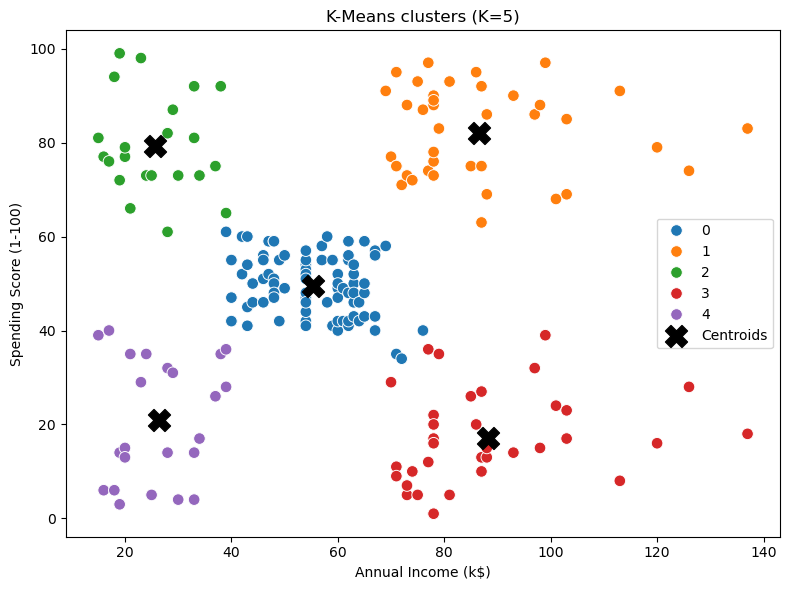

In [12]:
centroids = scaler.inverse_transform(kmeans.cluster_centers_)
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df, x=features[0], y=features[1],
    hue="Cluster", palette="tab10", s=70
)
plt.scatter(centroids[:, 0], centroids[:, 1],
            marker="X", s=250, c="black", label="Centroids")
plt.title(f"K-Means clusters (K={best_k})")
plt.legend()
plt.tight_layout()
plt.show()